
0. EXHAUSTIVE COMPONENT CORNER ANALYSIS

Architecture A — 2x OPA2320
  Number of corners: 128
  Worst alias response: -65.03 dB
  Required maximum: -66.52 dB
  Compliance margin: -1.49 dB
  Verdict: FAIL
  Worst-case component values:
    c_ac     = 1.2e-05
    r_in     = 1010
    r_fb     = 49500
    c_fb     = 2.09e-10
    ra       = 9900
    ca       = 1.425e-09
    cb       = 7.125e-10

1. TAYLOE BASEBAND
RF source resistance: 8.22 ohm
Tayloe switch Ron: 5.00 ohm
Four-phase audio source: 52.88 ohm
20m cutoff: 1.368 MHz
40m cutoff: 0.700 MHz
Front-end insertion loss: 0.00 dB

2. PASSIVE RC2 OPTIMIZATION
R1: 1.00 ohm
R2: 48048.10 ohm
C1: 314.239 nF
C2: 0.352 nF
Passband minimum: -0.689 dB
Alias maximum: -52.053 dB
Required settling: 2600.66 ns
Available acquisition: 2600.00 ns
Feasible: False

3. ADC SETTLING
Arch A         Rth=   100.00 ohm | tau=   0.600 ns | required=   5.407 ns | PASS
Passive RC2    Rth= 48101.98 ohm | tau= 288.612 ns | required=2600.656 ns | FAIL

Arch B ideali

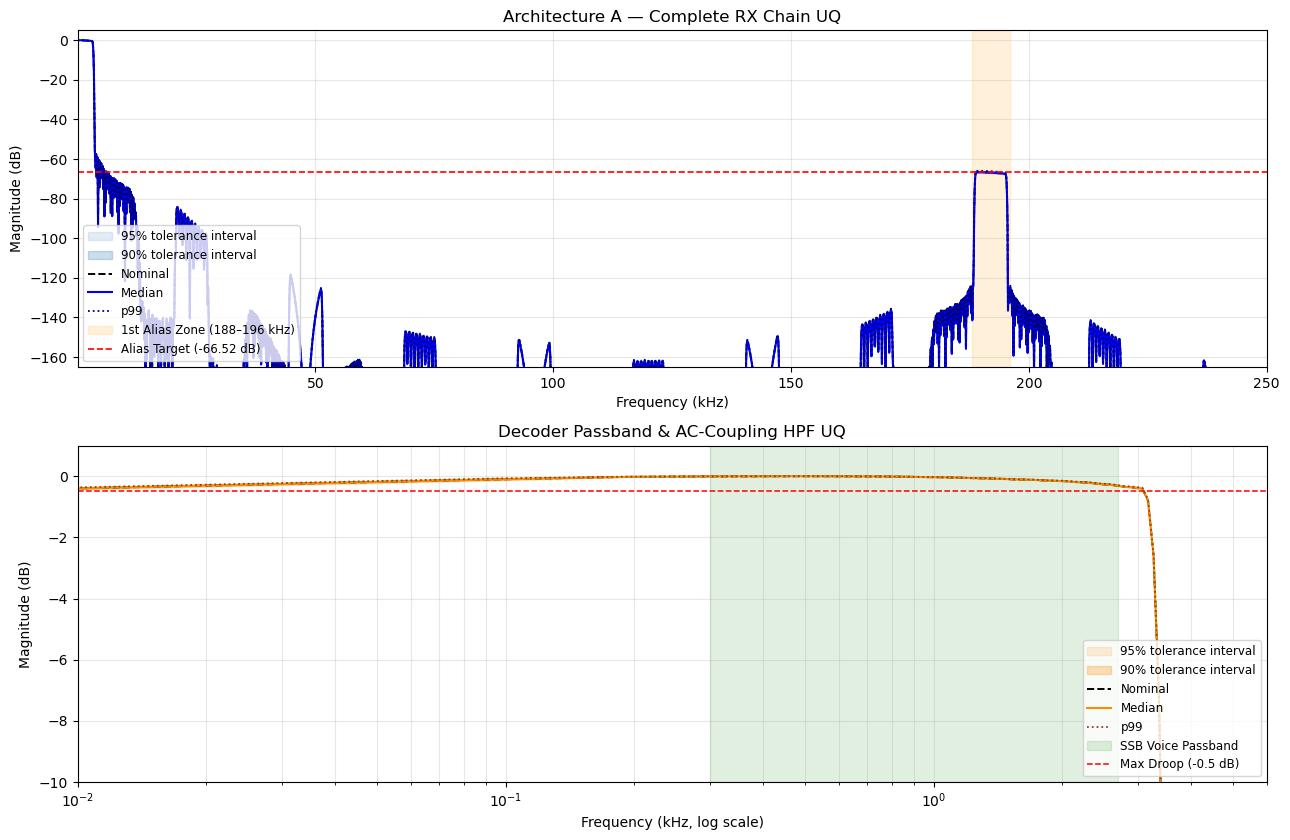


6. REV 40N FINAL SUMMARY
Sampling frequency:       192.0 kHz
Output sampling rate:     8.0 kHz
SSB bandwidth:            2.70 kHz
Alias evaluation zone:    188.0–196.0 kHz
Alias rejection target:   66.52 dB
ADC reference:            3.10 V
ADC resolution:           12 bits
ADC LSB:                  0.7568 mV
ADC acquisition budget:   2600 ns
Arch A settling:          5.41 ns
Passive RC2 feasible:     False
Arch A corner:            FAIL

END OF REV 40N ANALYSIS


In [1]:
# ============================================================
# REV 40N — COMPLETE RX AUDIO FILTER CHAIN
# Corrected engineering analysis model
#
# Architectures:
#   A: 2x OPA2320, 4 op-amps, differential gain + AAF
#   B: 3x OPA2320, 6 op-amps, unity-gain AAF + pole 3
#
# Compliance:
#   - Enumerated component tolerance corners
#   - Truncated Gaussian Monte Carlo
#   - Uniform Monte Carlo reference
#   - Per-run worst-over-alias percentile statistics
#
# IMPORTANT:
#   Frequency responses are normalized to the low-frequency
#   signal gain. Amplifier gain is handled separately in the
#   noise and clipping calculations.
# ============================================================

import itertools
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import firwin, freqz
from scipy.optimize import differential_evolution
from scipy.special import erfinv

# ============================================================
# 1. CONFIGURATION
# ============================================================

FS = 192e3
FS1 = 48e3
FS2 = 24e3
FSOUT = 8e3

R_DEC = 4
N_CIC = 4

SSB = 2.7e3
FSOUT_NYQ = FSOUT / 2

FCRIT = FS - FSOUT_NYQ
FCRIT_HI = FS + FSOUT_NYQ

BLOCKER_DBFS = -30.0
ALIAS_BELOW_NOISE_DB = 10.0
ADC_SNR_TYP = 68.0

ADC_VREF = 3.10
ADC_BITS = 12
ADC_FS_PEAK = ADC_VREF / 2
ADC_LSB = ADC_VREF / (2**ADC_BITS)
ADC_FS_DBM = 10.0

ADC_SNR_NOISE_DBFS = -ADC_SNR_TYP - 10 * np.log10(FS / SSB)

ALIAS_THRESHOLD_DBFS = ADC_SNR_NOISE_DBFS - ALIAS_BELOW_NOISE_DB

REQUIRED_REJECTION_DB = BLOCKER_DBFS - ALIAS_THRESHOLD_DBFS

TARGET = -REQUIRED_REJECTION_DB
MAX_PASS_LOSS_DB = 0.5

L_FRONTEND_DB = 0.0

# ============================================================
# 2. TAYLOE MODEL
# ============================================================

R_SOURCE_RF = 8.22
R_ON_TAYLOE = 5.0

C_TAYLOE_20M = 2.2e-9
C_TAYLOE_40M = 4.3e-9

R_SOURCE_AUDIO = 4 * (R_SOURCE_RF + R_ON_TAYLOE)

FC_TAYLOE_20M = 1 / (2 * np.pi * R_SOURCE_AUDIO * C_TAYLOE_20M)
FC_TAYLOE_40M = 1 / (2 * np.pi * R_SOURCE_AUDIO * C_TAYLOE_40M)

# Default analysis band
FC_TAYLOE = FC_TAYLOE_20M

# ============================================================
# 3. ARCHITECTURE A COMPONENTS
# ============================================================

C_AC = 10e-6

R1_DIFF = 1e3
RFB_DIFF = 50e3
CFB_DIFF = 220e-12

RA_SK = 10e3
CA_SK = 1.5e-9
CB_SK = 750e-12

R_KICK = 100.0
C_KICK = 1e-9

GAIN_A = RFB_DIFF / (R1_DIFF + R_SOURCE_AUDIO)
GAIN_A_DB = 20 * np.log10(GAIN_A)

# ============================================================
# 4. ARCHITECTURE B COMPONENTS
# ============================================================

# Equal-R, equal-C Butterworth Sallen-Key nominal design.
R_B_SK = 10e3
FC_B_SK = 14.7e3
C_B_SK = 1 / (2 * np.pi * R_B_SK * FC_B_SK)

R_P3 = 10e3
C_P3 = 1.08e-9

Q_SK = 1 / np.sqrt(2)

# ============================================================
# 5. ADC MODEL
# ============================================================

C_ADC = 6e-12
R_ADC_SWITCH = 0.0

T_ACQ = 2600e-9


def adc_settling(Rth, C=C_ADC, Rswitch=R_ADC_SWITCH):
    tau = (Rth + Rswitch) * C
    t_required = (ADC_BITS + 1) * np.log(2) * tau
    return tau, t_required


# ============================================================
# 6. TOLERANCE MODEL
# ============================================================

# (datasheet tolerance, assumed bin yield)

PASSIVE_MODEL = {
    "C0G": (0.05, 0.99),
    "X5R": (0.20, 0.95),
    "R1pct": (0.01, 0.99),
    "L10pct": (0.10, 0.95),
}


def tol_to_sigma(tol, yield_):
    return tol / (np.sqrt(2) * erfinv(yield_))


def draw_by_class(rng, cls, n, dist="truncnorm"):
    tol, yield_ = PASSIVE_MODEL[cls]

    if dist == "uniform":
        return rng.uniform(1 - tol, 1 + tol, n)

    if dist == "worstcase":
        return rng.choice([1 - tol, 1 + tol], size=n)

    if dist != "truncnorm":
        raise ValueError(f"Unknown distribution: {dist}")

    sigma = tol_to_sigma(tol, yield_)

    result = np.empty(n)
    filled = 0

    while filled < n:
        samples = rng.normal(0, sigma, n - filled)
        samples = samples[np.abs(samples) <= tol]

        count = len(samples)
        result[filled : filled + count] = 1 + samples
        filled += count

    return result


# ============================================================
# 7. GENERAL UTILITIES
# ============================================================


def db(x):
    return 20 * np.log10(np.maximum(np.abs(x), 1e-15))


def wrap(f, fs):
    return (np.asarray(f) + fs / 2) % fs - fs / 2


def tayloe(f):
    return 1 / (1 + 1j * np.asarray(f) / FC_TAYLOE)


def butter(f, n, fc):
    f = np.asarray(f, float)
    return 1 / np.sqrt(1 + (f / fc) ** (2 * n))


def sallen_key(f, fc, Q=Q_SK):
    s = 1j * np.asarray(f) / fc
    return 1 / (1 + s**2 + s / Q)


# ============================================================
# 8. ANALOG TRANSFER FUNCTIONS
# ============================================================


def arch_a_old(
    f,
    c_ac=C_AC,
    r_in=R1_DIFF,
    r_fb=RFB_DIFF,
    c_fb=CFB_DIFF,
    ra=RA_SK,
    ca=CA_SK,
    cb=CB_SK,
    r_k=R_KICK,
    c_k=C_KICK,
):

    f = np.asarray(f, float)
    s = 2j * np.pi * f

    r_in_total = r_in + R_SOURCE_AUDIO

    H_hp = s * r_in_total * c_ac / (1 + s * r_in_total * c_ac)

    H_p1 = 1 / (1 + s * r_fb * c_fb)

    w0_sq = 1 / (ra**2 * ca * cb)
    a1 = 2 * ra * cb

    H_sk = w0_sq / (s**2 + s * a1 * w0_sq + w0_sq)

    H_kick = 1 / (1 + s * r_k * c_k)

    return H_hp * H_p1 * H_sk * H_kick


def arch_a(
    f,
    c_ac=C_AC,
    r_in=R1_DIFF,
    r_fb=RFB_DIFF,
    c_fb=CFB_DIFF,
    ra=RA_SK,
    ca=CA_SK,
    cb=CB_SK,
):  # r_k=R_KICK, c_k=C_KICK):

    f = np.asarray(f, float)
    s = 2j * np.pi * f

    # Differential amplifier input resistance
    r_in_total = r_in + R_SOURCE_AUDIO

    # AC coupling
    H_hp = s * r_in_total * c_ac / (1 + s * r_in_total * c_ac)

    # Differential amplifier feedback pole
    H_p1 = 1 / (1 + s * r_fb * c_fb)

    # Actual differential amplifier gain
    gain = r_fb / r_in_total

    # Component-derived Sallen-Key natural frequency
    w0 = 1 / (ra * np.sqrt(ca * cb))

    # Component-derived Sallen-Key Q
    Q = np.sqrt(ca / cb) / 2

    H_sk = w0**2 / (s**2 + s * w0 / Q + w0**2)

    # # Output isolation / ADC kickback network
    # H_kick = 1/(1+s*r_k*c_k)
    # return H_hp*H_p1*H_sk*H_kick
    return H_hp * H_p1 * H_sk


def arch_b(f, c_ac=C_AC, r_sk=R_B_SK, c_sk=C_B_SK, r_p3=R_P3, c_p3=C_P3):

    f = np.asarray(f, float)
    s = 2j * np.pi * f

    r_input = 1e6 + R_SOURCE_AUDIO

    H_hp = s * r_input * c_ac / (1 + s * r_input * c_ac)

    fc_sk = 1 / (2 * np.pi * r_sk * c_sk)

    H_sk = sallen_key(f, fc_sk)

    H_p3 = 1 / (1 + s * r_p3 * c_p3)

    return H_hp * H_sk * H_p3


# ============================================================
# 9. DIGITAL CHAIN
# ============================================================

HB = firwin(63, 12e3, fs=FS1)
POLY = firwin(161, 3.35e3, fs=FS2)


def cic(f):
    f = np.asarray(f, float)

    den = 4 * np.sin(np.pi * f / FS)
    num = np.sin(4 * np.pi * f / FS)

    ratio = np.ones_like(f)
    mask = np.abs(den) > 1e-12

    ratio[mask] = num[mask] / den[mask]

    return np.abs(ratio) ** 4


def fir_response(f, coeff, fs):
    _, h = freqz(coeff, worN=2 * np.pi * np.asarray(f) / fs)
    return np.abs(h)


def digital(f):
    f = np.asarray(f, float)

    h1 = cic(wrap(f, FS))
    h2 = fir_response(wrap(f, FS1), HB, FS1)
    h3 = fir_response(wrap(f, FS2), POLY, FS2)

    return h1 * h2 * h3


def complete(f, architecture):
    h_digital = digital(f)

    if architecture == "A":
        h_analog = arch_a(f)
    # elif architecture == "B":
    #     h_analog = arch_b(f)
    else:
        raise ValueError(architecture)

    return tayloe(f) * h_analog * h_digital


# ============================================================
# 10. PASSIVE RC2 OPTIMIZATION
# ============================================================

R_ADC_LEAK = 1e12
f_pass = np.linspace(300, SSB, 250)
f_alias = np.linspace(FCRIT, FCRIT_HI, 500)


def passive_rc(f, R1, R2, C1, C2):
    f = np.atleast_1d(np.asarray(f, float))
    s = 2j * np.pi * f

    G1 = 1 / (R_SOURCE_AUDIO + R1)
    G2 = 1 / R2
    GL = 1 / R_ADC_LEAK

    b = np.array([G1, 0], dtype=complex)

    result = np.empty(len(f), dtype=complex)

    for i, si in enumerate(s):
        A = np.array(
            [[G1 + G2 + si * C1, -G2], [-G2, G2 + GL + si * C2]], dtype=complex
        )

        result[i] = np.linalg.solve(A, b)[1]

    return result


def passive_objective(x):
    R1, R2, C1, C2 = 10 ** np.asarray(x)

    hp = db(passive_rc(f_pass, R1, R2, C1, C2))
    ha = db(passive_rc(f_alias, R1, R2, C1, C2))

    _, t_req = adc_settling(R_SOURCE_AUDIO + R1 + R2)

    pass_violation = max(0, -np.min(hp) - MAX_PASS_LOSS_DB)

    alias_violation = max(0, np.max(ha) - TARGET)

    settle_violation = max(0, (t_req - T_ACQ) / T_ACQ)

    return alias_violation**2 + 1000 * pass_violation**2 + 1000 * settle_violation**2


result = differential_evolution(
    passive_objective,
    [(0, 5), (0, 5), (-12, -5), (-12, -5)],
    seed=42,
    popsize=20,
    maxiter=400,
    tol=1e-7,
    polish=True,
)

R1_OPT, R2_OPT, C1_OPT, C2_OPT = 10**result.x

HP_OPT = db(passive_rc(f_pass, R1_OPT, R2_OPT, C1_OPT, C2_OPT))

HA_OPT = db(passive_rc(f_alias, R1_OPT, R2_OPT, C1_OPT, C2_OPT))

_, T_REQ_OPT = adc_settling(R_SOURCE_AUDIO + R1_OPT + R2_OPT)

PASSIVE_FEASIBLE = (
    np.min(HP_OPT) >= -MAX_PASS_LOSS_DB
    and np.max(HA_OPT) <= TARGET
    and T_ACQ >= T_REQ_OPT
)


def section(title):
    print("\n" + "=" * 78)
    print(title)
    print("=" * 78)


# ============================================================
# 11. CORNER ANALYSIS
# ============================================================

section("0. EXHAUSTIVE COMPONENT CORNER ANALYSIS")

COMPONENTS_A = [
    ("c_ac", C_AC, "X5R"),
    ("r_in", R1_DIFF, "R1pct"),
    ("r_fb", RFB_DIFF, "R1pct"),
    ("c_fb", CFB_DIFF, "C0G"),
    ("ra", RA_SK, "R1pct"),
    ("ca", CA_SK, "C0G"),
    ("cb", CB_SK, "C0G"),
    # ("r_k", R_KICK, "R1pct"),
    # ("c_k", C_KICK, "C0G"),
]

COMPONENTS_B = [
    ("c_ac", C_AC, "X5R"),
    ("r_sk", R_B_SK, "R1pct"),
    ("c_sk", C_B_SK, "C0G"),
    ("r_p3", R_P3, "R1pct"),
    ("c_p3", C_P3, "C0G"),
]


def corner_worst(architecture, f_grid):

    if architecture != "A":
        raise ValueError(f"Unsupported architecture: {architecture}")

    components = COMPONENTS_A if architecture == "A" else COMPONENTS_B

    mask = (f_grid >= FCRIT) & (f_grid <= FCRIT_HI)

    h_dig = digital(f_grid)
    h_tay = tayloe(f_grid)

    worst = -np.inf
    worst_signs = None

    for signs in itertools.product((-1, 1), repeat=len(components)):

        kwargs = {
            name: nominal * (1 + sign * PASSIVE_MODEL[cls][0])
            for (name, nominal, cls), sign in zip(components, signs)
        }

        if architecture == "A":
            h = arch_a(f_grid, **kwargs)
        # elif architecture == "B":
        #    h = arch_b(f_grid, **kwargs)
        else:
            raise Exception(f"Unsupported architecture: {architecture}")

        response = db(h_tay * h * h_dig)
        value = float(np.max(response[mask]))

        if value > worst:
            worst = value
            worst_signs = signs

    return worst, worst_signs, components


# Frequency grid covering the complete alias evaluation band.
f_corner = np.linspace(FCRIT, FCRIT_HI, 2001)

corner_results = {}

arch_map = [
    ("A", "Architecture A — 2x OPA2320"),
    # ("B", "Architecture B — 3x OPA2320"),
]

for arch_key, arch_name in arch_map:

    worst_db, worst_signs, components = corner_worst(arch_key, f_corner)

    margin = TARGET - worst_db
    passed = worst_db <= TARGET

    corner_results[arch_key] = {
        "worst_db": worst_db,
        "worst_signs": worst_signs,
        "components": components,
        "margin_db": margin,
        "passed": passed,
    }

    print(f"\n{arch_name}")
    print(f"  Number of corners: {2**len(components)}")
    print(f"  Worst alias response: {worst_db:+.2f} dB")
    print(f"  Required maximum: {TARGET:+.2f} dB")
    print(f"  Compliance margin: {margin:+.2f} dB")
    print(f"  Verdict: {'PASS' if passed else 'FAIL'}")

    print("  Worst-case component values:")

    for (name, nominal, cls), sign in zip(components, worst_signs):
        tolerance = PASSIVE_MODEL[cls][0]
        value = nominal * (1 + sign * tolerance)

        print(f"    {name:<8} = {value:.6g}")

# ============================================================
# 12. MONTE CARLO
# ============================================================


def simulate_mc(architecture, f_grid, n_runs=5000, dist="truncnorm", seed=42):

    rng = np.random.default_rng(seed)

    h_dig = digital(f_grid)
    h_tay = tayloe(f_grid)

    mask = (f_grid >= FCRIT) & (f_grid <= FCRIT_HI)

    if architecture != "A":
        raise ValueError(f"Unsupported architecture: {architecture}")

    components = COMPONENTS_A if architecture == "A" else COMPONENTS_B

    factors = {}

    for name, nominal, cls in components:
        factors[name] = draw_by_class(rng, cls, n_runs, dist)

    mc = np.empty((n_runs, len(f_grid)))

    if architecture == "A":
        nominal = db(h_tay * arch_a(f_grid) * h_dig)
    # elif architecture == "B":
    #    nominal = db(h_tay*arch_b(f_grid)*h_dig)
    else:
        raise Exception(f"Unsupported architecture: {architecture}")

    for k in range(n_runs):

        kwargs = {
            name: nominal_value * factors[name][k]
            for name, nominal_value, cls in components
        }

        if architecture == "A":
            h = arch_a(f_grid, **kwargs)
        # elif architecture == "B":
        #    h = arch_b(f_grid, **kwargs)
        else:
            raise Exception(f"Unsupported architecture: {architecture}")

        mc[k] = db(h_tay * h * h_dig)

    # Critical: maximum is taken within each run first.
    worst_per_run = np.max(mc[:, mask], axis=1)

    return {
        "mc": mc,
        "nominal": nominal,
        "worst_per_run": worst_per_run,
        "alias_mask": mask,
    }


# ============================================================
# 13. MONTE CARLO PLOTS
# ============================================================



def plot_audio_uq(architecture, f_grid, n_runs=5000):

    r = simulate_mc(architecture, f_grid, n_runs=n_runs, dist="truncnorm")

    mc = r["mc"]
    nominal = r["nominal"]
    worst = r["worst_per_run"]

    print(f"\nArchitecture {architecture} — Alias rejection statistics")
    print("-" * 68)
    print(f"{'Level':<10} {'Quantile':>11} {'Response':>13} {'Margin':>12} {'Verdict':>9}")
    print("-" * 68)

    levels = [
        ("Median", 50),
        ("1 sigma", 84.1345),
        ("2 sigma", 97.7250),
        ("3 sigma", 99.8650),
        ("4 sigma", 99.99683),
        ("5 sigma", 99.9999713),
        ("6 sigma", 99.9999999),
        ("Maximum", 100),
    ]

    for label, q in levels:
        value = np.percentile(worst, q)
        margin = TARGET - value
        verdict = "PASS" if margin >= 0 else "FAIL"

        print(
            f"{label:<10} {q:>10.5f}% "
            f"{value:>+12.2f} dB "
            f"{margin:>+10.2f} dB "
            f"{verdict:>9}"
        )

    print("-" * 68)

    p2_5, p5, p50, p95, p97_5, p99 = [
        np.percentile(mc, p, axis=0)
        for p in (2.5, 5, 50, 95, 97.5, 99)
    ]

    f_khz = f_grid / 1e3

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8.5))

    # --------------------------------------------------------
    # COMPLETE RX CHAIN
    # --------------------------------------------------------

    ax1.fill_between(
        f_khz, p2_5, p97_5,
        alpha=0.14, color="steelblue",
        label="95% tolerance interval"
    )

    ax1.fill_between(
        f_khz, p5, p95,
        alpha=0.28, color="steelblue",
        label="90% tolerance interval"
    )

    ax1.plot(f_khz, nominal, "k--", lw=1.4, label="Nominal")
    ax1.plot(f_khz, p50, color="blue", lw=1.5, label="Median")
    ax1.plot(f_khz, p99, ":", color="navy", lw=1.3, label="p99")

    ax1.axvspan(
        FCRIT / 1e3, FCRIT_HI / 1e3,
        color="orange", alpha=0.15,
        label="1st Alias Zone (188–196 kHz)"
    )

    ax1.axhline(
        TARGET, color="red", ls="--", lw=1.2,
        label=f"Alias Target ({TARGET:.2f} dB)"
    )

    ax1.set_xlim(0.01, 250)
    ax1.set_ylim(-165, 5)
    ax1.set_title(
        f"Architecture {architecture} — Complete RX Chain UQ"
    )
    ax1.set_xlabel("Frequency (kHz)")
    ax1.set_ylabel("Magnitude (dB)")
    ax1.grid(alpha=0.3)
    ax1.legend(loc="lower left", fontsize=8.5)

    # --------------------------------------------------------
    # DECODER PASSBAND
    # --------------------------------------------------------

    ax2.fill_between(
        f_khz, p2_5, p97_5,
        alpha=0.14, color="darkorange",
        label="95% tolerance interval"
    )

    ax2.fill_between(
        f_khz, p5, p95,
        alpha=0.28, color="darkorange",
        label="90% tolerance interval"
    )

    ax2.plot(f_khz, nominal, "k--", lw=1.4, label="Nominal")
    ax2.plot(f_khz, p50, color="darkorange", lw=1.5, label="Median")
    ax2.plot(f_khz, p99, ":", color="saddlebrown", lw=1.3, label="p99")

    ax2.axvspan(
        0.3, SSB / 1e3,
        color="green", alpha=0.12,
        label="SSB Voice Passband"
    )

    ax2.axhline(
        -MAX_PASS_LOSS_DB, color="red", ls="--", lw=1.1,
        label=f"Max Droop (-{MAX_PASS_LOSS_DB} dB)"
    )

    ax2.set_xscale("log")
    ax2.set_xlim(0.01, 6.0)
    ax2.set_ylim(-10, 1)
    ax2.set_title("Decoder Passband & AC-Coupling HPF UQ")
    ax2.set_xlabel("Frequency (kHz, log scale)")
    ax2.set_ylabel("Magnitude (dB)")
    ax2.grid(True, which="both", alpha=0.3)
    ax2.legend(loc="lower right", fontsize=8.5)

    plt.tight_layout()
    plt.show()

    return r
    
# ============================================================
# 14. SECTION 1 — TAYLOE
# ============================================================

section("1. TAYLOE BASEBAND")

print(f"RF source resistance: {R_SOURCE_RF:.2f} ohm")
print(f"Tayloe switch Ron: {R_ON_TAYLOE:.2f} ohm")
print(f"Four-phase audio source: {R_SOURCE_AUDIO:.2f} ohm")
print(f"20m cutoff: {FC_TAYLOE_20M/1e6:.3f} MHz")
print(f"40m cutoff: {FC_TAYLOE_40M/1e6:.3f} MHz")
print(f"Front-end insertion loss: {L_FRONTEND_DB:.2f} dB")


# ============================================================
# 15. SECTION 2 — PASSIVE RC2
# ============================================================

section("2. PASSIVE RC2 OPTIMIZATION")

print(f"R1: {R1_OPT:.2f} ohm")
print(f"R2: {R2_OPT:.2f} ohm")
print(f"C1: {C1_OPT*1e9:.3f} nF")
print(f"C2: {C2_OPT*1e9:.3f} nF")

print(f"Passband minimum: {np.min(HP_OPT):.3f} dB")
print(f"Alias maximum: {np.max(HA_OPT):.3f} dB")
print(f"Required settling: {T_REQ_OPT*1e9:.2f} ns")
print(f"Available acquisition: {T_ACQ*1e9:.2f} ns")
print(f"Feasible: {PASSIVE_FEASIBLE}")


# ============================================================
# 16. SECTION 3 — ADC SETTLING
# ============================================================

section("3. ADC SETTLING")

RTH_A = R_KICK
RTH_B = R_P3

for name, rth in [
    ("Arch A", RTH_A),
    # ("Arch B", RTH_B),
    ("Passive RC2", R_SOURCE_AUDIO + R1_OPT + R2_OPT),
]:

    tau, required = adc_settling(rth)

    print(
        f"{name:<14} Rth={rth:9.2f} ohm | "
        f"tau={tau*1e9:8.3f} ns | "
        f"required={required*1e9:8.3f} ns | "
        f"{'PASS' if T_ACQ >= required else 'FAIL'}"
    )


# Idealized charge sharing if C_P3 is directly connected
# to the ADC sampling capacitor during acquisition.
charge_error = C_ADC / (C_P3 + C_ADC)
charge_error_lsb = charge_error * (2**ADC_BITS)

print("\nArch B idealized charge-sharing estimate:")
print(f"Error fraction: {100*charge_error:.4f}%")
print(f"Error in ADC LSB: {charge_error_lsb:.2f} LSB")


# ============================================================
# SECTION 8 — FINAL COMPLIANCE VERDICT
# ============================================================

section("4. FINAL DESIGN COMPLIANCE VERDICT")

corner_a_failed = not corner_results["A"]["passed"]
corner_b_failed = False  # not corner_results["B"]["passed"]

print(f"Compliance target: {TARGET:+.2f} dB")
print()

for arch_key, arch_name in arch_map:

    result = corner_results[arch_key]

    print(f"{arch_name}:")
    print(f"  Worst component corner: {result['worst_db']:+.2f} dB")
    print(f"  Required maximum:       {TARGET:+.2f} dB")
    print(f"  Compliance margin:      {result['margin_db']:+.2f} dB")
    print(f"  Verdict:                {'PASS' if result['passed'] else 'FAIL'}")
    print()

if corner_a_failed or corner_b_failed:

    section("VERDICT — CORNER FAIL")

    if corner_a_failed:
        print("Arch A: FAIL")

    if corner_b_failed:
        print("Arch B: FAIL")

    print()
    print("Do not claim component-tolerance compliance.")

else:

    section("VERDICT — CORNER PASS")

    print("Arch A: PASS")
    print("Arch B: PASS")
    print()
    print("Both architectures pass the enumerated")
    print("component-tolerance corner analysis.")

# ============================================================
# 5. ARCHITECTURE A MONTE CARLO ANALYSIS
# ============================================================

section("5. ARCHITECTURE A MONTE CARLO ANALYSIS")

mc_results_A = plot_audio_uq(
    architecture="A", f_grid=np.linspace(0, FS * 1.5, 3000), n_runs=5000
)

# ============================================================
# SECTION 10 — SUMMARY
# ============================================================

section("6. REV 40N FINAL SUMMARY")

print(f"Sampling frequency:       {FS/1e3:.1f} kHz")
print(f"Output sampling rate:     {FSOUT/1e3:.1f} kHz")
print(f"SSB bandwidth:            {SSB/1e3:.2f} kHz")
print(f"Alias evaluation zone:    {FCRIT/1e3:.1f}–{FCRIT_HI/1e3:.1f} kHz")
print(f"Alias rejection target:   {-TARGET:.2f} dB")
print(f"ADC reference:            {ADC_VREF:.2f} V")
print(f"ADC resolution:           {ADC_BITS} bits")
print(f"ADC LSB:                  {ADC_LSB*1e3:.4f} mV")
print(f"ADC acquisition budget:   {T_ACQ*1e9:.0f} ns")
print(f"Arch A settling:          {adc_settling(RTH_A)[1]*1e9:.2f} ns")
# print(f"Arch B settling:          {adc_settling(RTH_B)[1]*1e9:.2f} ns")
print(f"Passive RC2 feasible:     {PASSIVE_FEASIBLE}")
print(f"Arch A corner:            {'FAIL' if corner_a_failed else 'PASS'}")
# print(f"Arch B corner:            {'FAIL' if corner_b_failed else 'PASS'}")
print()
print("END OF REV 40N ANALYSIS")


In [5]:
# ============================================================
# 17. DISCRETE-PART OPTIMIZATION (NLP seed -> sequential MILP -> exact corners)
# ============================================================
from scipy.optimize import minimize, milp, LinearConstraint, Bounds

# Extra tolerance classes (tighter C0G costs more)
PASSIVE_MODEL.update({"C0G2": (0.02, 0.99), "C0G1": (0.01, 0.99)})
CAP_CLASSES = {"C0G": 0.0, "C0G2": 0.15, "C0G1": 0.50}   # relative cost
PAR_COST = 0.04                                          # two caps in parallel

E24 = np.array([1.0, 1.1, 1.2, 1.3, 1.5, 1.6, 1.8, 2.0, 2.2, 2.4, 2.7, 3.0,
                3.3, 3.6, 3.9, 4.3, 4.7, 5.1, 5.6, 6.2, 6.8, 7.5, 8.2, 9.1])
E96 = np.round(10 ** (np.arange(96) / 96), 2)   # close to the real E96 (a few values differ by 1 digit)

CAP_POOL = np.concatenate([E24 * d for d in (1e-12, 10e-12, 100e-12, 1e-9)])
CAP_POOL = CAP_POOL[(CAP_POOL >= 47e-12) & (CAP_POOL <= 10e-9)]
R_POOL = np.concatenate([E96 * d for d in (1e3, 10e3)])
R_POOL = R_POOL[(R_POOL >= 4e3) & (R_POOL <= 30e3)]

OPT = ["c_fb", "ra", "ca", "cb"]                  # chosen from discrete pools
FIXED = {"c_ac": C_AC, "r_in": R1_DIFF, "r_fb": RFB_DIFF}
FIXED_CLASS = {"c_ac": "X5R", "r_in": "R1pct", "r_fb": "R1pct"}
ALL = OPT + list(FIXED)
COMPONENT_CLASS = {
    **FIXED_CLASS,
    "ra": "R1pct",
    "c_fb": "C0G",
    "ca": "C0G",
    "cb": "C0G",
}

F_A = np.linspace(FCRIT, FCRIT_HI, 401)
F_P = np.linspace(300, SSB, 120)
_DIG_A = tayloe(F_A) * digital(F_A)
_DIG_P = tayloe(F_P) * digital(F_P)


def metrics(x):
    """alias = worst response in alias band [dB], passdev = max |passband deviation| [dB]."""
    alias = np.max(db(_DIG_A * arch_a(F_A, **x)))
    passdev = np.max(np.abs(db(_DIG_P * arch_a(F_P, **x))))
    return np.array([alias, passdev])


def jacobian(x, eps=1e-3):
    """d metric / d ln(component) for all 7 components -> dict name -> array(2)"""
    J = {}
    for n in ALL:
        xp, xm = dict(x), dict(x)
        xp[n] *= np.exp(eps)
        xm[n] *= np.exp(-eps)
        J[n] = (metrics(xp) - metrics(xm)) / (2 * eps)
    return J


def full_x(chosen):
    return {**FIXED, **chosen}


# ---------- Step 1 (replacement): bounded seed, minimal change subject to limits ----------
Q_MIN, Q_MAX = 0.60, 0.85

def q_of(x):
    return np.sqrt(x["ca"] / x["cb"]) / 2

def continuous_seed(margin_alias=1.0, margin_pass=0.1, span=0.20):
    nom = {"c_fb": CFB_DIFF, "ra": RA_SK, "ca": CA_SK, "cb": CB_SK}
    u_nom = np.log([nom[n] for n in OPT])
    lo_u, hi_u = u_nom + np.log(1 - span), u_nom + np.log(1 + span)

    def worst_case(x):
        m = metrics(x)
        J = jacobian(x)
        tols = {
            n: PASSIVE_MODEL[COMPONENT_CLASS[n]][0]
            for n in ALL
        }
        return m + sum(np.abs(J[n]) * tols[n] for n in ALL)

    def obj(u):
        u = np.clip(u, lo_u, hi_u)
        x = full_x({n: float(np.exp(v)) for n, v in zip(OPT, u)})
        wc = worst_case(x)
        q = q_of(x)
        pen = (max(0.0, wc[0] - (TARGET - margin_alias)) ** 2 * 100.0
               + max(0.0, wc[1] - (MAX_PASS_LOSS_DB - margin_pass)) ** 2 * 1e3
               + max(0.0, Q_MIN - q) ** 2 * 1e3
               + max(0.0, q - Q_MAX) ** 2 * 1e3)
        return np.sum((u - u_nom) ** 2) * 10 + pen   # stay close to a sane design

    r = minimize(obj, u_nom, method="Nelder-Mead",
                 options={"maxiter": 1500, "xatol": 1e-5, "fatol": 1e-7})
    u = np.clip(r.x, lo_u, hi_u)
    seed = {n: float(np.exp(v)) for n, v in zip(OPT, u)}
    x = full_x(seed)
    print(f"  seed Q={q_of(x):.3f}, "
          f"f_p1={1/(2*np.pi*RFB_DIFF*seed['c_fb'])/1e3:.2f} kHz, "
          f"f_sk={1/(2*np.pi*seed['ra']*np.sqrt(seed['ca']*seed['cb']))/1e3:.2f} kHz")
    return seed

# ---------- Step 2: candidate generation ----------
def build_candidates(name, x_star, max_par=2, window=0.12):   # was 0.30
    if name == "ra":
        pool, classes, npar_max = R_POOL, {"R1pct": 0.0}, 1
    else:
        pool, classes, npar_max = CAP_POOL, CAP_CLASSES, max_par
    lo, hi = x_star * (1 - window), x_star * (1 + window)

    combos = [(v, f"{v*1e12:.0f}p" if v < 1e-9 else f"{v*1e9:.2f}n", 1)
              for v in pool if lo <= v <= hi]
    if npar_max >= 2:
        for i, a in enumerate(pool):
            for b in pool[i:]:
                if lo <= a + b <= hi:
                    combos.append((a + b, f"{a*1e12:.0f}p+{b*1e12:.0f}p", 2))
    if name == "ra":
        combos = [(v, f"{v/1e3:.3g}k", 1) for v in pool if lo <= v <= hi]
    assert combos, f"no candidates for {name}"

    cands = []
    for v, lbl, npar in combos:
        for cls, cost in classes.items():
            cands.append(dict(v=v, label=lbl, cls=cls,
                              tol=PASSIVE_MODEL[cls][0],
                              cost=cost + PAR_COST * (npar - 1)))
    return cands


# ---------- Step 3: one MILP solve, linearized around x_lin ----------
def solve_milp(x_lin, x_star, cands, limits, w_dev=1.0, slack_w=200.0):
    xf = full_x(x_lin)
    m0 = metrics(xf)
    J = jacobian(xf)

    offs, cur = {}, 0
    for n in OPT:
        offs[n] = cur
        cur += len(cands[n])
    i_sa, i_sp = cur, cur + 1
    nv = cur + 2

    integrality = np.r_[np.ones(cur), 0, 0]
    lb_v, ub_v = np.zeros(nv), np.r_[np.ones(cur), np.inf, np.inf]

    c = np.zeros(nv)
    for n in OPT:
        for k, cd in enumerate(cands[n]):
            c[offs[n] + k] = w_dev * abs(np.log(cd["v"] / x_star[n])) + cd["cost"]
    c[i_sa] = c[i_sp] = slack_w

    rows, lo, hi = [], [], []
    for n in OPT:                              # one-hot per component
        r = np.zeros(nv)
        r[offs[n]:offs[n] + len(cands[n])] = 1
        rows.append(r); lo.append(1); hi.append(1)

    const_fixed = sum(np.abs(J[n]) * PASSIVE_MODEL[FIXED_CLASS[n]][0] for n in FIXED)
    for mi, i_slack in ((0, i_sa), (1, i_sp)):
        r = np.zeros(nv)
        for n in OPT:
            for k, cd in enumerate(cands[n]):
                r[offs[n] + k] = (J[n][mi] * (np.log(cd["v"]) - np.log(x_lin[n]))
                                  + abs(J[n][mi]) * cd["tol"])
        r[i_slack] = -1
        rows.append(r); lo.append(-np.inf)
        hi.append(limits[mi] - m0[mi] - const_fixed[mi])

    sol = milp(c=c, integrality=integrality, bounds=Bounds(lb_v, ub_v),
               constraints=LinearConstraint(np.array(rows), lo, hi))
    if not sol.success:
        return None
    pick = {}
    for n in OPT:
        k = int(np.argmax(sol.x[offs[n]:offs[n] + len(cands[n])]))
        pick[n] = cands[n][k]
    return pick, sol.x[i_sa], sol.x[i_sp]


# ---------- Step 4: exact corner enumeration of the discrete design ----------
def exact_corners(pick):
    x = full_x({n: pick[n]["v"] for n in OPT})
    tols = {n: pick[n]["tol"] for n in OPT}
    tols.update({n: PASSIVE_MODEL[FIXED_CLASS[n]][0] for n in FIXED})
    worst = np.array([-np.inf, -np.inf])
    for signs in itertools.product((-1, 1), repeat=len(ALL)):
        xc = {n: x[n] * (1 + s * tols[n]) for n, s in zip(ALL, signs)}
        worst = np.maximum(worst, metrics(xc))
    return worst


# ---------- Driver ----------
def optimize_arch_a(max_par=2, margins=(0.5, 1.0, 1.5, 2.0), margin_pass=0.1):
    best = None
    for margin in margins:
        x_star = continuous_seed(margin_alias=margin + 0.5, margin_pass=margin_pass)
        cands = {n: build_candidates(n, x_star[n], max_par) for n in OPT}
        limits = (TARGET - margin, MAX_PASS_LOSS_DB - margin_pass)
        x_lin = dict(x_star)
        pick = None
        for it in range(5):                    # sequential re-linearization
            res = solve_milp(x_lin, x_star, cands, limits)
            if res is None:
                break
            new_pick, sa, sp = res
            new_x = {n: new_pick[n]["v"] for n in OPT}
            converged = pick is not None and all(
                new_pick[n]["v"] == pick[n]["v"] and new_pick[n]["cls"] == pick[n]["cls"]
                for n in OPT)
            pick, x_lin = new_pick, new_x
            if converged:
                break
        if pick is None:
            print(f"margin {margin:.1f} dB: MILP failed")
            continue

        xq = full_x({n: pick[n]["v"] for n in OPT})
        if not (Q_MIN <= q_of(xq) <= Q_MAX):
            print(f"margin {margin:.1f} dB: Q={q_of(xq):.2f} out of range, skipped")
            continue

        wc_alias, wc_pass = exact_corners(pick)
        ok = wc_alias <= TARGET and wc_pass <= MAX_PASS_LOSS_DB
        print(f"\nlinear-margin target {margin:.1f} dB -> "
              f"exact corner alias {wc_alias:+.2f} dB (limit {TARGET:+.2f}), "
              f"passband dev {wc_pass:.3f} dB (limit {MAX_PASS_LOSS_DB}) "
              f"{'PASS' if ok else 'FAIL'}")
        print("   " + ", ".join(f"{n}={pick[n]['label']} [{pick[n]['cls']}]" for n in OPT))
        if ok and best is None:
            best = pick
            break
    return best


# ---------- Monte Carlo on the discrete result ----------
def mc_check(pick, n_runs=5000, seed=1):
    rng = np.random.default_rng(seed)
    comps = [(n, pick[n]["v"], pick[n]["cls"]) for n in OPT] + \
            [(n, FIXED[n], FIXED_CLASS[n]) for n in FIXED]
    fac = {n: draw_by_class(rng, cls, n_runs, "truncnorm") for n, _, cls in comps}
    nom = dict((n, v) for n, v, _ in comps)
    worst = np.empty(n_runs)
    for k in range(n_runs):
        x = {n: nom[n] * fac[n][k] for n in nom}
        worst[k] = np.max(db(_DIG_A * arch_a(F_A, **x)))
    print(f"\nMC ({n_runs} runs): median {np.median(worst):+.2f} dB, "
          f"p99.9 {np.percentile(worst, 99.9):+.2f} dB, max {worst.max():+.2f} dB, "
          f"target {TARGET:+.2f} dB")
    return worst


section("7. DISCRETE PART OPTIMIZATION (ARCH A)")
best_pick = optimize_arch_a(max_par=2)
if best_pick:
    mc_check(best_pick)
else:
    print("No design met the corner limits. Allow lower poles, 4th pole, or tighter classes.")


7. DISCRETE PART OPTIMIZATION (ARCH A)
  seed Q=0.707, f_p1=14.47 kHz, f_sk=12.50 kHz

linear-margin target 0.5 dB -> exact corner alias -68.34 dB (limit -66.52), passband dev 0.389 dB (limit 0.5) PASS
   c_fb=220p [C0G], ra=12.1k [R1pct], ca=1.50n [C0G], cb=750p [C0G]

MC (5000 runs): median -69.92 dB, p99.9 -69.08 dB, max -68.94 dB, target -66.52 dB



ANALOG BANDWIDTH COMPARISON
------------------------------------------------
Original -3 dB corner:   11.040 kHz
MILP optimized corner:   9.850 kHz
Corner shift:            -1.190 kHz
Relative shift:          -10.78%


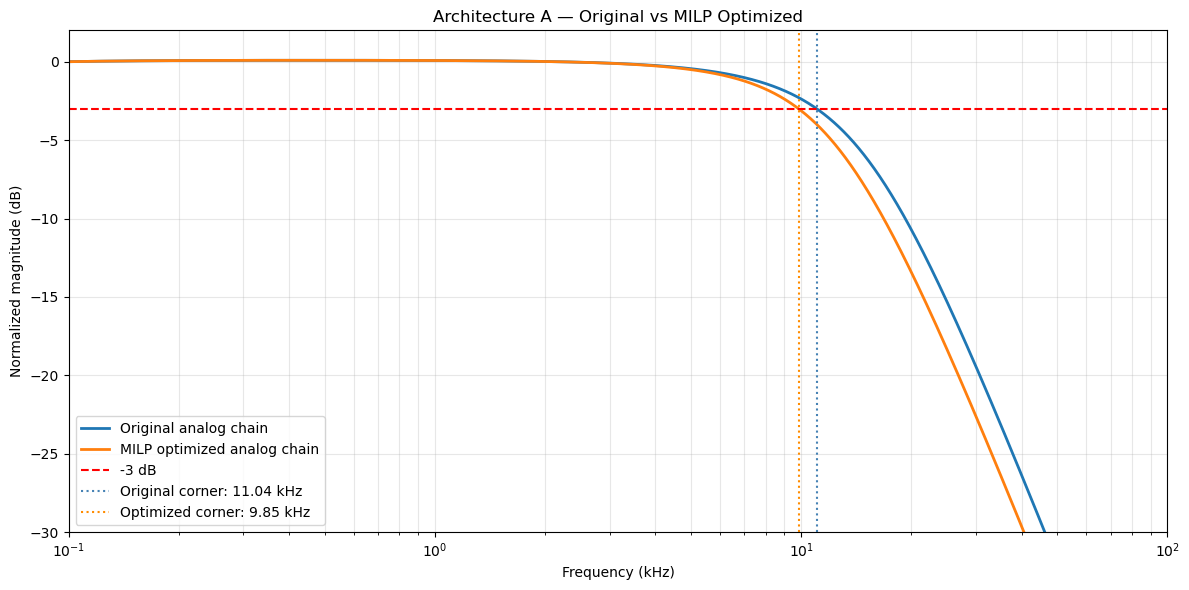


Architecture A — Alias rejection statistics
--------------------------------------------------------------------
Level         Quantile      Response       Margin   Verdict
--------------------------------------------------------------------
Median       50.00000%       -69.95 dB      +3.43 dB      PASS
1 sigma      84.13450%       -69.65 dB      +3.13 dB      PASS
2 sigma      97.72500%       -69.37 dB      +2.85 dB      PASS
3 sigma      99.86500%       -69.13 dB      +2.61 dB      PASS
4 sigma      99.99683%       -69.05 dB      +2.53 dB      PASS
5 sigma      99.99997%       -69.04 dB      +2.52 dB      PASS
6 sigma     100.00000%       -69.04 dB      +2.52 dB      PASS
Maximum     100.00000%       -69.04 dB      +2.52 dB      PASS
--------------------------------------------------------------------


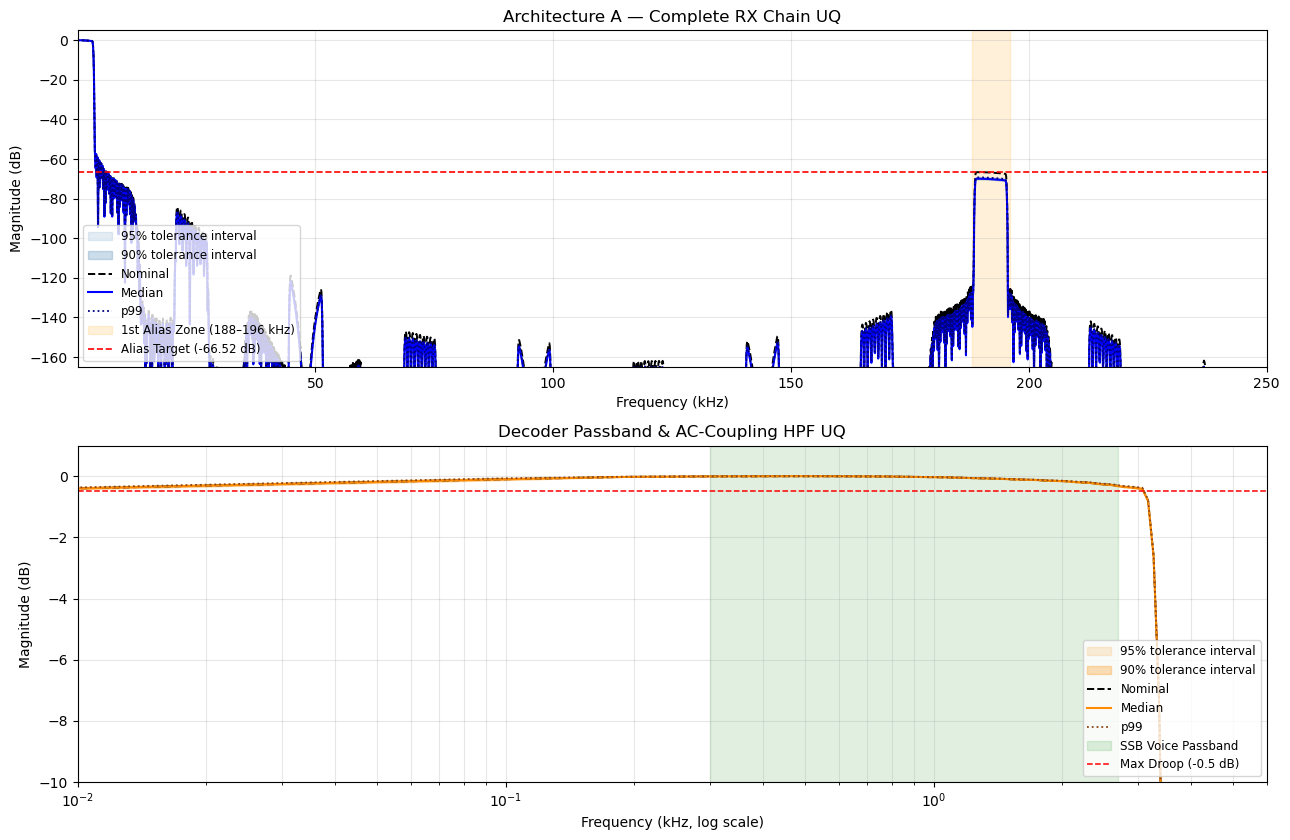

In [16]:

# ============================================================
# MILP OPTIMIZED DESIGN — CORNER FREQUENCY + UQ PLOTS
# ============================================================

_original = COMPONENTS_A, CFB_DIFF, RA_SK, CA_SK, CB_SK

# Original component values
original_values = {
    "c_ac": C_AC,
    "r_in": R1_DIFF,
    "r_fb": RFB_DIFF,
    "c_fb": CFB_DIFF,
    "ra": RA_SK,
    "ca": CA_SK,
    "cb": CB_SK,
}

# Apply MILP optimized components
optimized_values = {
    "c_ac": C_AC,
    "r_in": R1_DIFF,
    "r_fb": RFB_DIFF,
    "c_fb": best_pick["c_fb"]["v"],
    "ra": best_pick["ra"]["v"],
    "ca": best_pick["ca"]["v"],
    "cb": best_pick["cb"]["v"],
}

CFB_DIFF = optimized_values["c_fb"]
RA_SK = optimized_values["ra"]
CA_SK = optimized_values["ca"]
CB_SK = optimized_values["cb"]

COMPONENTS_A = [
    ("c_ac", C_AC, "X5R"),
    ("r_in", R1_DIFF, "R1pct"),
    ("r_fb", RFB_DIFF, "R1pct"),
    ("c_fb", CFB_DIFF, "C0G"),
    ("ra", RA_SK, "R1pct"),
    ("ca", CA_SK, "C0G"),
    ("cb", CB_SK, "C0G"),
]

# ------------------------------------------------------------
# Calculate actual normalized analog -3 dB corner
# ------------------------------------------------------------

def analog_response(x, f):
    return db(
        arch_a(f, **x) /
        abs(arch_a(np.array([100.0]), **x)[0])
    )

def corner_3db(x):
    f = np.logspace(1, 6, 30000)
    response = analog_response(x, f)

    crossings = np.where(
        (response[:-1] > -3.0103) &
        (response[1:] <= -3.0103)
    )[0]

    if len(crossings) == 0:
        return np.nan

    i = crossings[0]

    return np.interp(
        -3.0103,
        response[i:i+2][::-1],
        f[i:i+2][::-1]
    )

f_corner_original = corner_3db(original_values)
f_corner_optimized = corner_3db(optimized_values)

print("\nANALOG BANDWIDTH COMPARISON")
print("-" * 48)
print(f"Original -3 dB corner:   {f_corner_original/1e3:.3f} kHz")
print(f"MILP optimized corner:   {f_corner_optimized/1e3:.3f} kHz")
print(f"Corner shift:            {(f_corner_optimized-f_corner_original)/1e3:+.3f} kHz")
print(f"Relative shift:          {100*(f_corner_optimized/f_corner_original-1):+.2f}%")

# ------------------------------------------------------------
# Plot analog response comparison
# ------------------------------------------------------------

f_plot = np.logspace(2, 5.5, 5000)

H_original_db = analog_response(original_values, f_plot)
H_optimized_db = analog_response(optimized_values, f_plot)

plt.figure(figsize=(12, 6))

plt.semilogx(
    f_plot/1e3, H_original_db,
    lw=2, label="Original analog chain"
)

plt.semilogx(
    f_plot/1e3, H_optimized_db,
    lw=2, label="MILP optimized analog chain"
)

plt.axhline(-3.0103, color="red", ls="--", label="-3 dB")

plt.axvline(
    f_corner_original/1e3,
    color="steelblue", ls=":",
    label=f"Original corner: {f_corner_original/1e3:.2f} kHz"
)

plt.axvline(
    f_corner_optimized/1e3,
    color="darkorange", ls=":",
    label=f"Optimized corner: {f_corner_optimized/1e3:.2f} kHz"
)

plt.xlim(0.1, 100)
plt.ylim(-30, 2)
plt.xlabel("Frequency (kHz)")
plt.ylabel("Normalized magnitude (dB)")
plt.title("Architecture A — Original vs MILP Optimized")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Monte Carlo UQ — MILP optimized components
# ------------------------------------------------------------

mc_results_MILP = plot_audio_uq(
    architecture="A",
    f_grid=np.linspace(0, FS * 1.5, 3000),
    n_runs=5000
)

# ------------------------------------------------------------
# Restore original definitions
# ------------------------------------------------------------

COMPONENTS_A, CFB_DIFF, RA_SK, CA_SK, CB_SK = _original


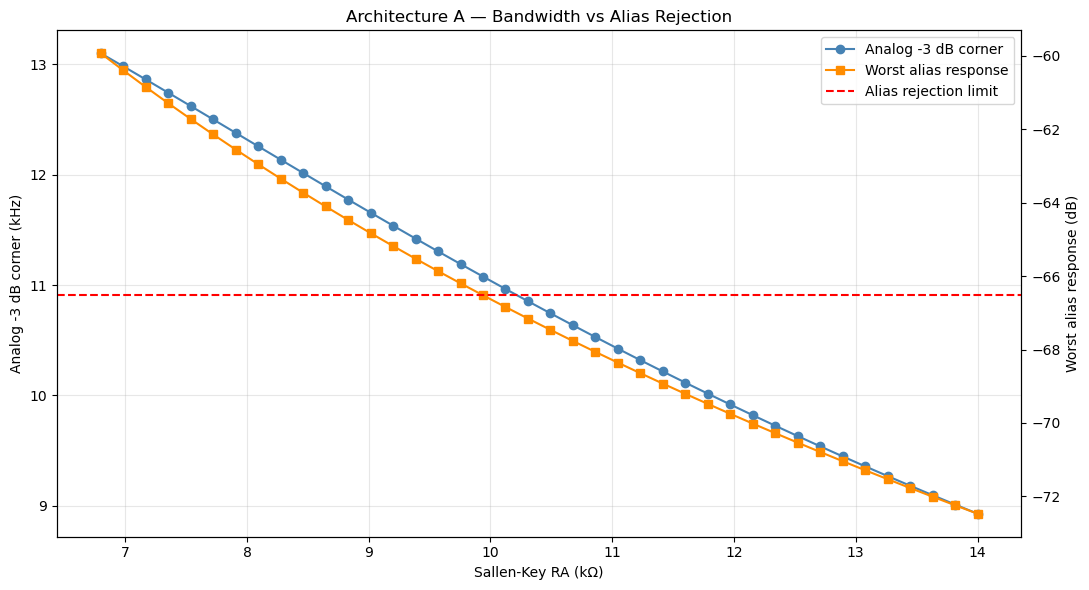

In [18]:
# ============================================================
# SALLEN-KEY FREQUENCY TRADE-OFF SWEEP
# ============================================================

ra_values = np.linspace(6.8e3, 14e3, 40)

f_sweep = np.linspace(100, 100e3, 10000)

results = []

for ra in ra_values:

    x = {
        "c_ac": C_AC,
        "r_in": R1_DIFF,
        "r_fb": RFB_DIFF,
        "c_fb": best_pick["c_fb"]["v"],
        "ra": ra,
        "ca": best_pick["ca"]["v"],
        "cb": best_pick["cb"]["v"],
    }

    fc = corner_3db(x)

    alias_response = db(
        tayloe(f_alias) *
        arch_a(f_alias, **x) *
        digital(f_alias)
    )

    worst_alias = np.max(alias_response)

    results.append((ra, fc, worst_alias))

results = np.array(results)

fig, ax1 = plt.subplots(figsize=(11, 6))

ax1.plot(
    results[:, 0] / 1e3,
    results[:, 1] / 1e3,
    "o-", color="steelblue",
    label="Analog -3 dB corner"
)

ax1.set_xlabel("Sallen-Key RA (kΩ)")
ax1.set_ylabel("Analog -3 dB corner (kHz)")
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()

ax2.plot(
    results[:, 0] / 1e3,
    results[:, 2],
    "s-", color="darkorange",
    label="Worst alias response"
)

ax2.axhline(
    TARGET, color="red", ls="--",
    label="Alias rejection limit"
)

ax2.set_ylabel("Worst alias response (dB)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="best"
)

plt.title("Architecture A — Bandwidth vs Alias Rejection")
plt.tight_layout()
plt.show()

Feedback pole:       14.47 kHz
Second-order f0:     15.01 kHz
Second-order Q:      0.707


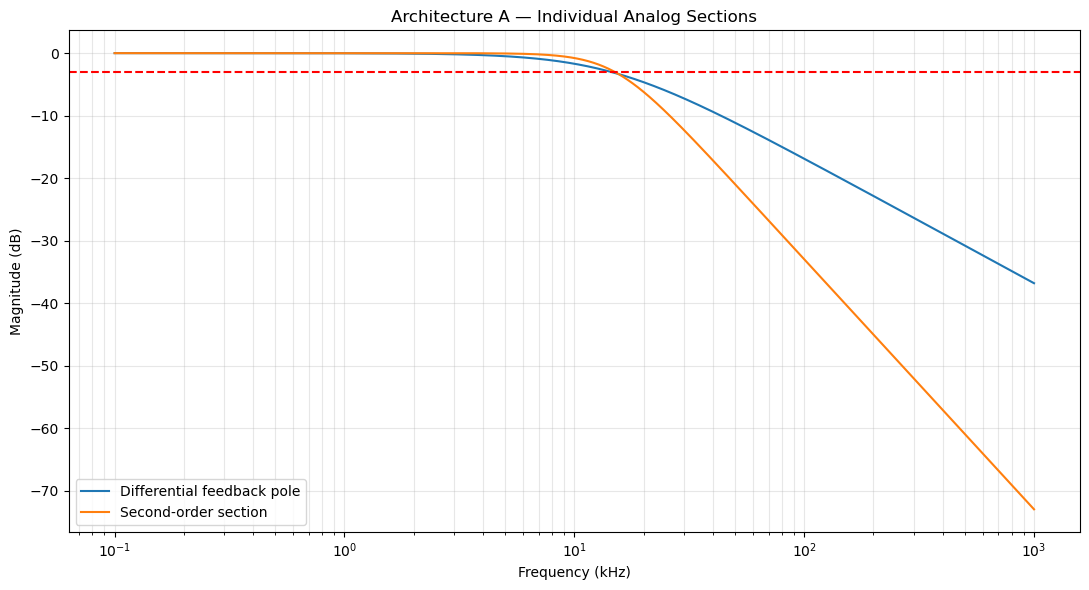

In [19]:

# ============================================================
# ARCHITECTURE A — INDIVIDUAL POLE DIAGNOSTICS
# ============================================================

fp1 = 1 / (2 * np.pi * RFB_DIFF * CFB_DIFF)

w0 = 1 / (RA_SK * np.sqrt(CA_SK * CB_SK))
f0 = w0 / (2 * np.pi)

Q = np.sqrt(CA_SK / CB_SK) / 2

print(f"Feedback pole:       {fp1/1e3:.2f} kHz")
print(f"Second-order f0:     {f0/1e3:.2f} kHz")
print(f"Second-order Q:      {Q:.3f}")

# Isolated section responses
f = np.logspace(2, 6, 5000)
s = 2j * np.pi * f

H_p1 = 1 / (1 + s * RFB_DIFF * CFB_DIFF)

H_second = w0**2 / (
    s**2 + s*w0/Q + w0**2
)

plt.figure(figsize=(11, 6))

plt.semilogx(f/1e3, db(H_p1), label="Differential feedback pole")
plt.semilogx(f/1e3, db(H_second), label="Second-order section")

plt.axhline(-3.0103, color="red", ls="--")
plt.xlabel("Frequency (kHz)")
plt.ylabel("Magnitude (dB)")
plt.title("Architecture A — Individual Analog Sections")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [25]:
# ============================================================
# 17. MAXIMUM-BANDWIDTH DISCRETE OPTIMIZATION — ARCH A
# NLP seed -> sequential MILP -> exact corners -> Monte Carlo
# ============================================================

from scipy.optimize import minimize, milp, LinearConstraint, Bounds
import numpy as np
import itertools

PASSIVE_MODEL.update({"C0G2": (0.02, 0.99), "C0G1": (0.01, 0.99)})

CAP_CLASSES = {"C0G": 0.0, "C0G2": 0.15, "C0G1": 0.50}
PAR_COST = 0.04

E24 = np.array([
    1.0, 1.1, 1.2, 1.3, 1.5, 1.6, 1.8, 2.0, 2.2, 2.4,
    2.7, 3.0, 3.3, 3.6, 3.9, 4.3, 4.7, 5.1, 5.6, 6.2,
    6.8, 7.5, 8.2, 9.1
])

E96 = np.round(10 ** (np.arange(96) / 96), 2)

CAP_POOL = np.concatenate([
    E24 * d for d in (1e-12, 10e-12, 100e-12, 1e-9)
])
CAP_POOL = CAP_POOL[(CAP_POOL >= 47e-12) & (CAP_POOL <= 10e-9)]

R_POOL = np.concatenate([E96 * 1e3, E96 * 10e3])
R_POOL = R_POOL[(R_POOL >= 4e3) & (R_POOL <= 30e3)]

OPT = ["c_fb", "ra", "ca", "cb"]

FIXED = {
    "c_ac": C_AC,
    "r_in": R1_DIFF,
    "r_fb": RFB_DIFF
}

FIXED_CLASS = {
    "c_ac": "X5R",
    "r_in": "R1pct",
    "r_fb": "R1pct"
}

COMPONENT_CLASS = {
    **FIXED_CLASS,
    "ra": "R1pct",
    "c_fb": "C0G",
    "ca": "C0G",
    "cb": "C0G"
}

F_A = np.linspace(FCRIT, FCRIT_HI, 401)
F_P = np.linspace(300, SSB, 120)

_DIG_A = tayloe(F_A) * digital(F_A)
_DIG_P = tayloe(F_P) * digital(F_P)

Q_MIN, Q_MAX = 0.60, 0.85


# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

def metrics(x):
    alias = np.max(db(_DIG_A * arch_a(F_A, **x)))
    passdev = np.max(np.abs(db(_DIG_P * arch_a(F_P, **x))))
    return np.array([alias, passdev])


def full_x(chosen):
    return {**FIXED, **chosen}


def q_of(x):
    return np.sqrt(x["ca"] / x["cb"]) / 2


def corner_frequency(x):
    return corner_analytic(x)


def jacobian(x, fn, eps=1e-4):
    J = {}
    for n in ALL:
        xp, xm = dict(x), dict(x)
        xp[n] *= np.exp(eps)
        xm[n] *= np.exp(-eps)
        J[n] = (fn(xp) - fn(xm)) / (2 * eps)
    return J


ALL = OPT + list(FIXED)


# ------------------------------------------------------------
# NLP seed
# ------------------------------------------------------------

def continuous_seed(span=0.30):

    nom = {
        "c_fb": CFB_DIFF,
        "ra": RA_SK,
        "ca": CA_SK,
        "cb": CB_SK
    }

    u0 = np.log([nom[n] for n in OPT])
    lo = u0 + np.log(1 - span)
    hi = u0 + np.log(1 + span)

    def objective(u):
        x = full_x({
            n: np.exp(v) for n, v in zip(OPT, u)
        })

        return -corner_frequency(x)

    def constraints(u):
        x = full_x({
            n: np.exp(v) for n, v in zip(OPT, u)
        })

        m = metrics(x)
        q = q_of(x)

        return np.array([
            TARGET - m[0],
            MAX_PASS_LOSS_DB - m[1],
            q - Q_MIN,
            Q_MAX - q
        ])

    result = minimize(
        objective,
        u0,
        method="SLSQP",
        bounds=list(zip(lo, hi)),
        constraints={"type": "ineq", "fun": constraints},
        options={"maxiter": 1500, "ftol": 1e-9}
    )

    u = np.clip(result.x, lo, hi)

    seed = {
        n: float(np.exp(v))
        for n, v in zip(OPT, u)
    }

    x = full_x(seed)

    print(
        f"Seed: fc={corner_frequency(x)/1e3:.2f} kHz, "
        f"Q={q_of(x):.4f}"
    )

    return seed


# ------------------------------------------------------------
# Candidate generation
# ------------------------------------------------------------

def build_candidates(name, x_star, max_par=2, window=0.30):

    if name == "ra":
        pool = R_POOL
        classes = {"R1pct": 0.0}
        npar_max = 1
    else:
        pool = CAP_POOL
        classes = CAP_CLASSES
        npar_max = max_par

    lo = x_star * (1 - window)
    hi = x_star * (1 + window)

    combos = [
        (v, f"{v*1e12:.0f}p" if v < 1e-9 else f"{v*1e9:.2f}n", 1)
        for v in pool if lo <= v <= hi
    ]

    if npar_max >= 2 and name != "ra":
        for i, a in enumerate(pool):
            for b in pool[i:]:
                if lo <= a + b <= hi:
                    combos.append((
                        a + b,
                        f"{a*1e12:.0f}p+{b*1e12:.0f}p",
                        2
                    ))

    candidates = []

    for v, label, npar in combos:
        for cls, cost in classes.items():
            candidates.append({
                "v": v,
                "label": label,
                "cls": cls,
                "tol": PASSIVE_MODEL[cls][0],
                "cost": cost + PAR_COST * (npar - 1)
            })

    assert candidates, f"No candidates for {name}"

    return candidates


# ------------------------------------------------------------
# MILP: MAXIMIZE BANDWIDTH
# ------------------------------------------------------------

def solve_milp(x_lin, x_star, cands, cost_weight=1e-5):

    xf = full_x(x_lin)

    m0 = metrics(xf)
    J = jacobian(xf, metrics)

    fc0 = corner_frequency(xf)
    Jfc = jacobian(xf, corner_frequency)

    offsets = {}
    cur = 0

    for n in OPT:
        offsets[n] = cur
        cur += len(cands[n])

    nv = cur

    integrality = np.ones(nv)
    lb = np.zeros(nv)
    ub = np.ones(nv)

    # MAXIMIZE linearized corner frequency.
    # scipy.milp minimizes, therefore negate the gradient.
    objective = np.zeros(nv)

    for n in OPT:
        for k, cd in enumerate(cands[n]):
            idx = offsets[n] + k

            dx = np.log(cd["v"] / x_lin[n])

            objective[idx] = (
                -Jfc[n] * dx
                + cost_weight * cd["cost"]
            )

    rows, lower, upper = [], [], []

    # One component selection per variable.
    for n in OPT:
        r = np.zeros(nv)
        r[offsets[n]:offsets[n] + len(cands[n])] = 1

        rows.append(r)
        lower.append(1)
        upper.append(1)

    # Robust alias and passband constraints.
    fixed_margin = np.zeros(2)

    for n in FIXED:
        fixed_margin += (
            np.abs(J[n]) *
            PASSIVE_MODEL[FIXED_CLASS[n]][0]
        )

    for mi in range(2):

        r = np.zeros(nv)

        for n in OPT:
            for k, cd in enumerate(cands[n]):

                dx = np.log(cd["v"] / x_lin[n])

                r[offsets[n] + k] = (
                    J[n][mi] * dx
                    + abs(J[n][mi]) * cd["tol"]
                )

        rows.append(r)
        lower.append(-np.inf)

        limit = (
            TARGET if mi == 0 else MAX_PASS_LOSS_DB
        )

        upper.append(
            limit - m0[mi] - fixed_margin[mi]
        )

    # Explicit robust Q constraints.
    # Q = sqrt(CA/CB)/2.
    #
    # Linear in binary candidate-selection variables
    # after taking logarithms.

    r_lower = np.zeros(nv)
    r_upper = np.zeros(nv)

    for n in ("ca", "cb"):

        sign = 1 if n == "ca" else -1

        for k, cd in enumerate(cands[n]):

            t = cd["tol"]

            nominal = np.log(cd["v"])

            r_lower[offsets[n] + k] = sign * (
                nominal + np.log(1 - t if n == "ca"
                                 else 1 + t)
            )

            r_upper[offsets[n] + k] = sign * (
                nominal + np.log(1 + t if n == "ca"
                                 else 1 - t)
            )

    rows.extend([r_lower, r_upper])

    lower.extend([
        2 * np.log(2 * Q_MIN),
        -np.inf
    ])

    upper.extend([
        np.inf,
        2 * np.log(2 * Q_MAX)
    ])

    sol = milp(
        c=objective,
        integrality=integrality,
        bounds=Bounds(lb, ub),
        constraints=LinearConstraint(
            np.array(rows),
            lower,
            upper
        )
    )

    if not sol.success:
        return None

    pick = {}

    for n in OPT:
        k = np.argmax(
            sol.x[
                offsets[n]:
                offsets[n] + len(cands[n])
            ]
        )

        pick[n] = cands[n][k]

    return pick


# ------------------------------------------------------------
# Exact tolerance-corner verification
# ------------------------------------------------------------

def exact_corners(pick):

    x = full_x({
        n: pick[n]["v"] for n in OPT
    })

    tols = {
        n: pick[n]["tol"] for n in OPT
    }

    tols.update({
        n: PASSIVE_MODEL[FIXED_CLASS[n]][0]
        for n in FIXED
    })

    worst = np.array([-np.inf, -np.inf])
    fc_min = np.inf
    fc_max = -np.inf

    for signs in itertools.product((-1, 1), repeat=len(ALL)):

        xc = {
            n: x[n] * (1 + s * tols[n])
            for n, s in zip(ALL, signs)
        }

        worst = np.maximum(worst, metrics(xc))

        fc = corner_frequency(xc)

        fc_min = min(fc_min, fc)
        fc_max = max(fc_max, fc)

        q = q_of(xc)

        if q < Q_MIN or q > Q_MAX:
            return worst, fc_min, fc_max, False

    return worst, fc_min, fc_max, True


# ------------------------------------------------------------
# Sequential MILP optimization
# ------------------------------------------------------------

def optimize_arch_a(max_par=2, window=0.30, iterations=12):

    x_star = continuous_seed()

    cands = {
        n: build_candidates(
            n, x_star[n], max_par=max_par, window=window
        )
        for n in OPT
    }

    x_lin = dict(x_star)
    best = None

    for it in range(iterations):

        pick = solve_milp(x_lin, x_star, cands)

        if pick is None:
            print(f"MILP infeasible at iteration {it+1}")
            break

        new_x = {
            n: pick[n]["v"] for n in OPT
        }

        x = full_x(new_x)

        wc, fc_min, fc_max, q_ok = exact_corners(pick)

        ok = (
            wc[0] <= TARGET
            and wc[1] <= MAX_PASS_LOSS_DB
            and q_ok
        )

        print(
            f"Iteration {it+1}: "
            f"fc={corner_frequency(x)/1e3:.2f} kHz, "
            f"worst-corner fc={fc_min/1e3:.2f} kHz, "
            f"Q={q_of(x):.4f}, "
            f"alias={wc[0]:.2f} dB, "
            f"pass={wc[1]:.3f} dB, "
            f"{'PASS' if ok else 'FAIL'}"
        )

        if ok:
            if best is None or fc_min > best[0]:
                best = (fc_min, pick.copy())

        if all(
            new_x[n] == x_lin[n] for n in OPT
        ):
            break

        x_lin = new_x

    if best is None:
        return None

    pick = best[1]

    print("\nMAXIMUM VERIFIED BANDWIDTH CANDIDATE")
    print(f"Worst-corner bandwidth: {best[0]/1e3:.2f} kHz")

    print("   " + ", ".join(
        f"{n}={pick[n]['label']} [{pick[n]['cls']}]"
        for n in OPT
    ))

    return pick


# ------------------------------------------------------------
# Monte Carlo
# ------------------------------------------------------------

def mc_check(pick, n_runs=5000, seed=1):

    rng = np.random.default_rng(seed)

    comps = (
        [(n, pick[n]["v"], pick[n]["cls"]) for n in OPT]
        + [(n, FIXED[n], FIXED_CLASS[n]) for n in FIXED]
    )

    fac = {
        n: draw_by_class(rng, cls, n_runs, "truncnorm")
        for n, _, cls in comps
    }

    nom = {n: v for n, v, _ in comps}

    worst = np.empty(n_runs)
    fc_mc = np.empty(n_runs)
    q_mc = np.empty(n_runs)

    for k in range(n_runs):

        x = {
            n: nom[n] * fac[n][k]
            for n in nom
        }

        worst[k] = np.max(db(_DIG_A * arch_a(F_A, **x)))
        fc_mc[k] = corner_frequency(x)
        q_mc[k] = q_of(x)

    print(
        f"\nMC alias: median={np.median(worst):.2f} dB, "
        f"p99.9={np.percentile(worst,99.9):.2f} dB, "
        f"max={worst.max():.2f} dB"
    )

    print(
        f"MC bandwidth: median={np.median(fc_mc)/1e3:.2f} kHz, "
        f"p1={np.percentile(fc_mc,1)/1e3:.2f} kHz"
    )

    print(
        f"MC Q: median={np.median(q_mc):.4f}, "
        f"p1={np.percentile(q_mc,1):.4f}, "
        f"p99={np.percentile(q_mc,99):.4f}"
    )

    return {
        "alias": worst,
        "corner": fc_mc,
        "q": q_mc
    }


# ============================================================
# RUN
# ============================================================

section("17. MAXIMUM-BANDWIDTH MILP OPTIMIZATION — ARCH A")

best_pick = optimize_arch_a(
    max_par=2,
    window=0.30,
    iterations=12
)

if best_pick:
    mc_results_MILP = mc_check(best_pick)
else:
    print("No verified feasible discrete design found.")


17. MAXIMUM-BANDWIDTH MILP OPTIMIZATION — ARCH A
Seed: fc=13.30 kHz, Q=0.8499
Iteration 1: fc=12.77 kHz, worst-corner fc=12.42 kHz, Q=0.8415, alias=-66.52 dB, pass=0.267 dB, FAIL
Iteration 2: fc=12.25 kHz, worst-corner fc=11.97 kHz, Q=0.8412, alias=-66.56 dB, pass=0.110 dB, PASS
Iteration 3: fc=12.51 kHz, worst-corner fc=12.15 kHz, Q=0.8408, alias=-66.55 dB, pass=0.301 dB, PASS
Iteration 4: fc=12.25 kHz, worst-corner fc=11.97 kHz, Q=0.8412, alias=-66.56 dB, pass=0.110 dB, PASS
Iteration 5: fc=12.51 kHz, worst-corner fc=12.15 kHz, Q=0.8408, alias=-66.55 dB, pass=0.301 dB, PASS
Iteration 6: fc=12.25 kHz, worst-corner fc=11.97 kHz, Q=0.8412, alias=-66.56 dB, pass=0.110 dB, PASS
Iteration 7: fc=12.51 kHz, worst-corner fc=12.15 kHz, Q=0.8408, alias=-66.55 dB, pass=0.301 dB, PASS
Iteration 8: fc=12.25 kHz, worst-corner fc=11.97 kHz, Q=0.8412, alias=-66.56 dB, pass=0.110 dB, PASS
Iteration 9: fc=12.51 kHz, worst-corner fc=12.15 kHz, Q=0.8408, alias=-66.55 dB, pass=0.301 dB, PASS
Iteration 10


ANALOG BANDWIDTH COMPARISON
------------------------------------------------
Original -3 dB corner:   11.040 kHz
MILP optimized corner:   12.507 kHz
Corner shift:            +1.468 kHz
Relative shift:          +13.29%


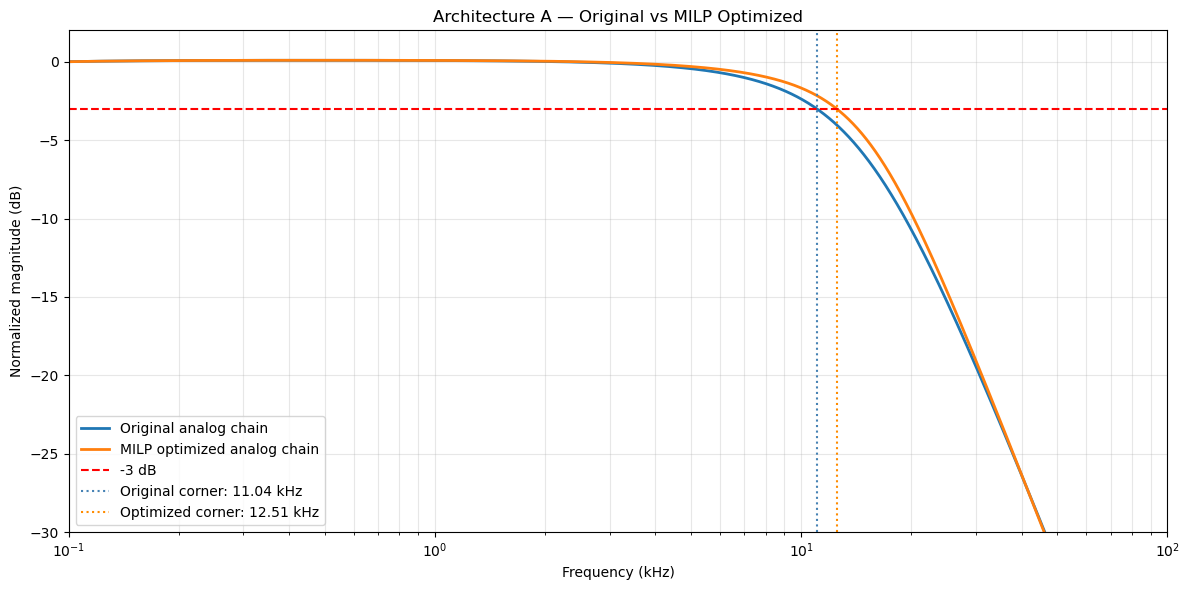


Architecture A — Alias rejection statistics
--------------------------------------------------------------------
Level         Quantile      Response       Margin   Verdict
--------------------------------------------------------------------
Median       50.00000%       -67.09 dB      +0.57 dB      PASS
1 sigma      84.13450%       -66.79 dB      +0.27 dB      PASS
2 sigma      97.72500%       -66.51 dB      -0.01 dB      FAIL
3 sigma      99.86500%       -66.27 dB      -0.25 dB      FAIL
4 sigma      99.99683%       -66.18 dB      -0.34 dB      FAIL
5 sigma      99.99997%       -66.18 dB      -0.34 dB      FAIL
6 sigma     100.00000%       -66.18 dB      -0.34 dB      FAIL
Maximum     100.00000%       -66.18 dB      -0.34 dB      FAIL
--------------------------------------------------------------------


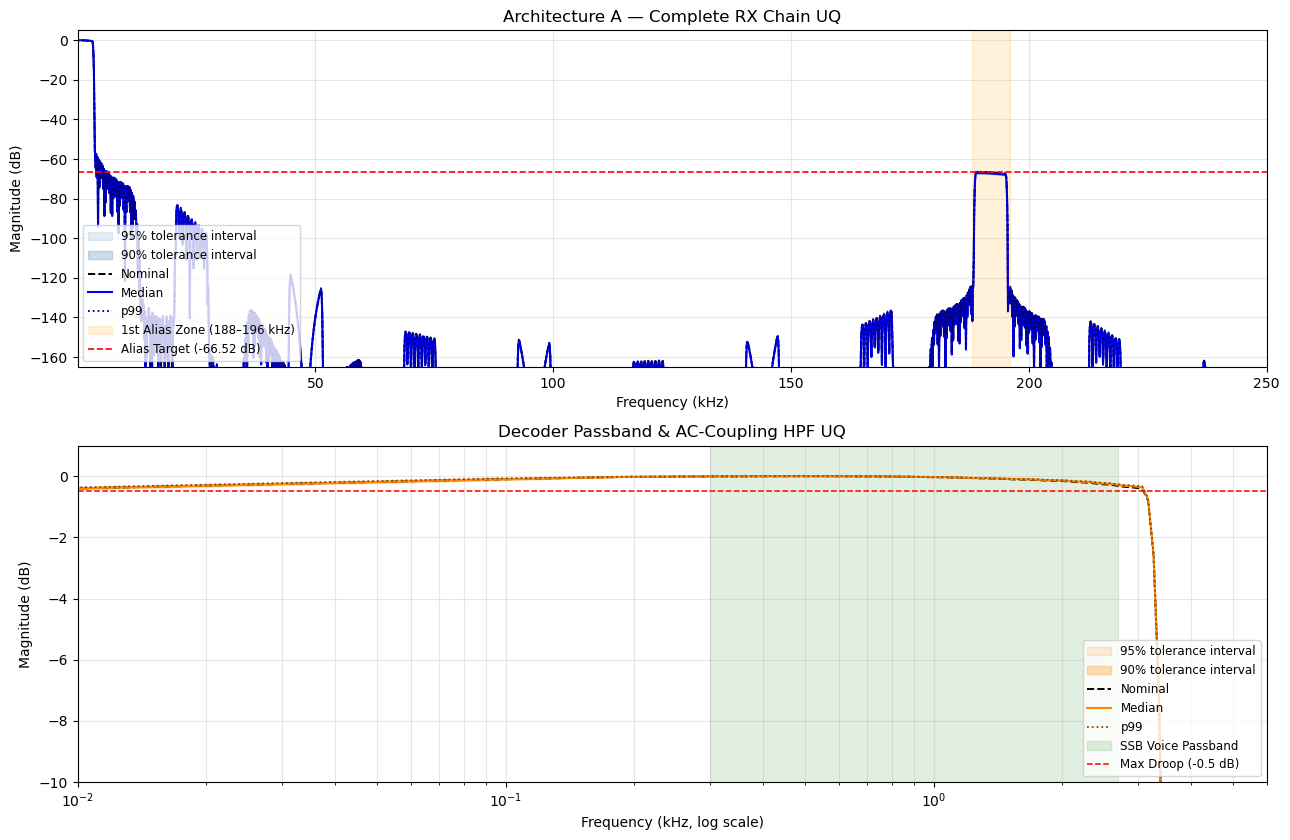

In [26]:

# ============================================================
# MILP OPTIMIZED DESIGN — CORNER FREQUENCY + UQ PLOTS
# ============================================================

_original = COMPONENTS_A, CFB_DIFF, RA_SK, CA_SK, CB_SK

# Original component values
original_values = {
    "c_ac": C_AC,
    "r_in": R1_DIFF,
    "r_fb": RFB_DIFF,
    "c_fb": CFB_DIFF,
    "ra": RA_SK,
    "ca": CA_SK,
    "cb": CB_SK,
}

# Apply MILP optimized components
optimized_values = {
    "c_ac": C_AC,
    "r_in": R1_DIFF,
    "r_fb": RFB_DIFF,
    "c_fb": best_pick["c_fb"]["v"],
    "ra": best_pick["ra"]["v"],
    "ca": best_pick["ca"]["v"],
    "cb": best_pick["cb"]["v"],
}

CFB_DIFF = optimized_values["c_fb"]
RA_SK = optimized_values["ra"]
CA_SK = optimized_values["ca"]
CB_SK = optimized_values["cb"]

COMPONENTS_A = [
    ("c_ac", C_AC, "X5R"),
    ("r_in", R1_DIFF, "R1pct"),
    ("r_fb", RFB_DIFF, "R1pct"),
    ("c_fb", CFB_DIFF, "C0G"),
    ("ra", RA_SK, "R1pct"),
    ("ca", CA_SK, "C0G"),
    ("cb", CB_SK, "C0G"),
]

# ------------------------------------------------------------
# Calculate actual normalized analog -3 dB corner
# ------------------------------------------------------------

def analog_response(x, f):
    return db(
        arch_a(f, **x) /
        abs(arch_a(np.array([100.0]), **x)[0])
    )

def corner_3db(x):
    f = np.logspace(1, 6, 30000)
    response = analog_response(x, f)

    crossings = np.where(
        (response[:-1] > -3.0103) &
        (response[1:] <= -3.0103)
    )[0]

    if len(crossings) == 0:
        return np.nan

    i = crossings[0]

    return np.interp(
        -3.0103,
        response[i:i+2][::-1],
        f[i:i+2][::-1]
    )

f_corner_original = corner_3db(original_values)
f_corner_optimized = corner_3db(optimized_values)

print("\nANALOG BANDWIDTH COMPARISON")
print("-" * 48)
print(f"Original -3 dB corner:   {f_corner_original/1e3:.3f} kHz")
print(f"MILP optimized corner:   {f_corner_optimized/1e3:.3f} kHz")
print(f"Corner shift:            {(f_corner_optimized-f_corner_original)/1e3:+.3f} kHz")
print(f"Relative shift:          {100*(f_corner_optimized/f_corner_original-1):+.2f}%")

# ------------------------------------------------------------
# Plot analog response comparison
# ------------------------------------------------------------

f_plot = np.logspace(2, 5.5, 5000)

H_original_db = analog_response(original_values, f_plot)
H_optimized_db = analog_response(optimized_values, f_plot)

plt.figure(figsize=(12, 6))

plt.semilogx(
    f_plot/1e3, H_original_db,
    lw=2, label="Original analog chain"
)

plt.semilogx(
    f_plot/1e3, H_optimized_db,
    lw=2, label="MILP optimized analog chain"
)

plt.axhline(-3.0103, color="red", ls="--", label="-3 dB")

plt.axvline(
    f_corner_original/1e3,
    color="steelblue", ls=":",
    label=f"Original corner: {f_corner_original/1e3:.2f} kHz"
)

plt.axvline(
    f_corner_optimized/1e3,
    color="darkorange", ls=":",
    label=f"Optimized corner: {f_corner_optimized/1e3:.2f} kHz"
)

plt.xlim(0.1, 100)
plt.ylim(-30, 2)
plt.xlabel("Frequency (kHz)")
plt.ylabel("Normalized magnitude (dB)")
plt.title("Architecture A — Original vs MILP Optimized")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Monte Carlo UQ — MILP optimized components
# ------------------------------------------------------------

mc_results_MILP = plot_audio_uq(
    architecture="A",
    f_grid=np.linspace(0, FS * 1.5, 3000),
    n_runs=5000
)

# ------------------------------------------------------------
# Restore original definitions
# ------------------------------------------------------------

COMPONENTS_A, CFB_DIFF, RA_SK, CA_SK, CB_SK = _original
